SHAP explainer

In [1]:
import os
os.chdir("..")  # run from the repo root so artifacts/ and data/ paths resolve

import pandas as pd
import shap
from src.data.ingestion import DataIngestion
from src.data.preprocessing import DataPreprocessing
from src.utils.helper import load_object

c:\Users\aishv\Documents\github_projects\churn-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_path, val_path, test_path = DataIngestion().initiate_data_ingestion()
X_train, X_val, X_test, y_train, y_val, y_test = (
    DataPreprocessing().initiate_data_preprocessing(train_path, val_path, test_path)
)

model = load_object("artifacts/model.pkl")
preprocessor = load_object("artifacts/preprocessor.pkl")
feature_names = preprocessor.get_feature_names_out()

In [3]:
X_sample = pd.DataFrame(X_test[:100], columns=feature_names)

In [4]:
feature_names

array(['numeric__tenure', 'numeric__MonthlyCharges', 'binary__Partner',
       'binary__Dependents', 'binary__PhoneService',
       'binary__PaperlessBilling', 'binary__MultipleLines',
       'binary__OnlineSecurity', 'binary__OnlineBackup',
       'binary__DeviceProtection', 'binary__TechSupport',
       'binary__StreamingTV', 'binary__StreamingMovies',
       'nominal__gender_Male', 'nominal__InternetService_Fiber optic',
       'nominal__InternetService_No', 'nominal__Contract_One year',
       'nominal__Contract_Two year',
       'nominal__PaymentMethod_Credit card (automatic)',
       'nominal__PaymentMethod_Electronic check',
       'nominal__PaymentMethod_Mailed check',
       'passthrough__SeniorCitizen'], dtype=object)

SHAP explainer

Testing with explanation module

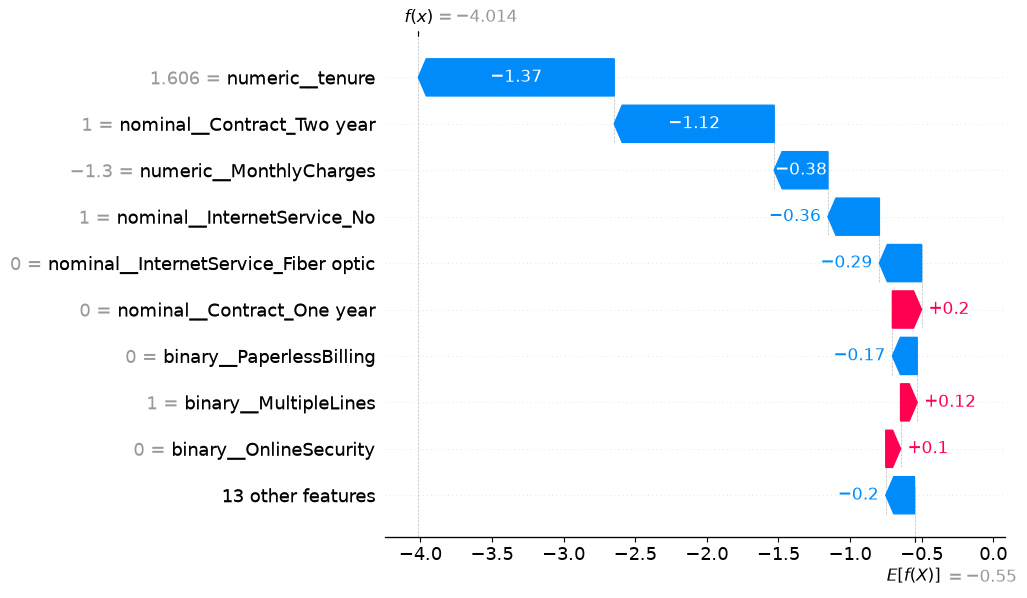

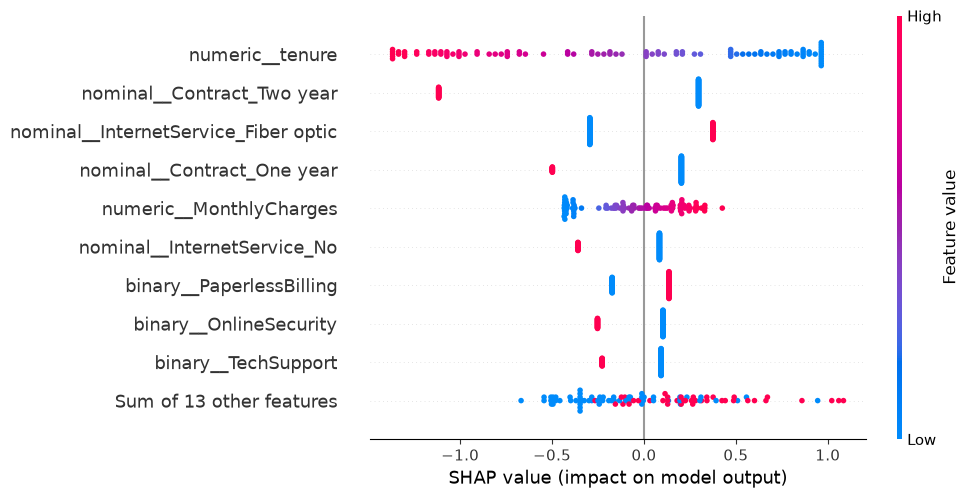

In [5]:
from src.models.explain import ChurnExplainer

background = pd.DataFrame(X_train, columns=feature_names).sample(100, random_state=42)
explainer = ChurnExplainer(model, background)

sv = explainer.explain(X_sample)
shap.plots.waterfall(sv[0])
shap.plots.beeswarm(sv)


In [6]:
raw_test = pd.read_csv(test_path)
original_cols = [c for c in raw_test.columns if c not in ("customerID", "Churn")]

explainer.top_reasons(X_sample.iloc[[0]], raw_test.iloc[[0]], original_cols)

[[{'feature': 'tenure',
   'value': 72,
   'impact': -1.368,
   'effect': 'decreases churn risk'},
  {'feature': 'Contract',
   'value': 'Two year',
   'impact': -0.913,
   'effect': 'decreases churn risk'},
  {'feature': 'InternetService',
   'value': 'No',
   'impact': -0.654,
   'effect': 'decreases churn risk'}]]

Checking output for a high risk customer

In [7]:
model.predict_proba(X_test)[:, 1].argmax()

np.int64(686)

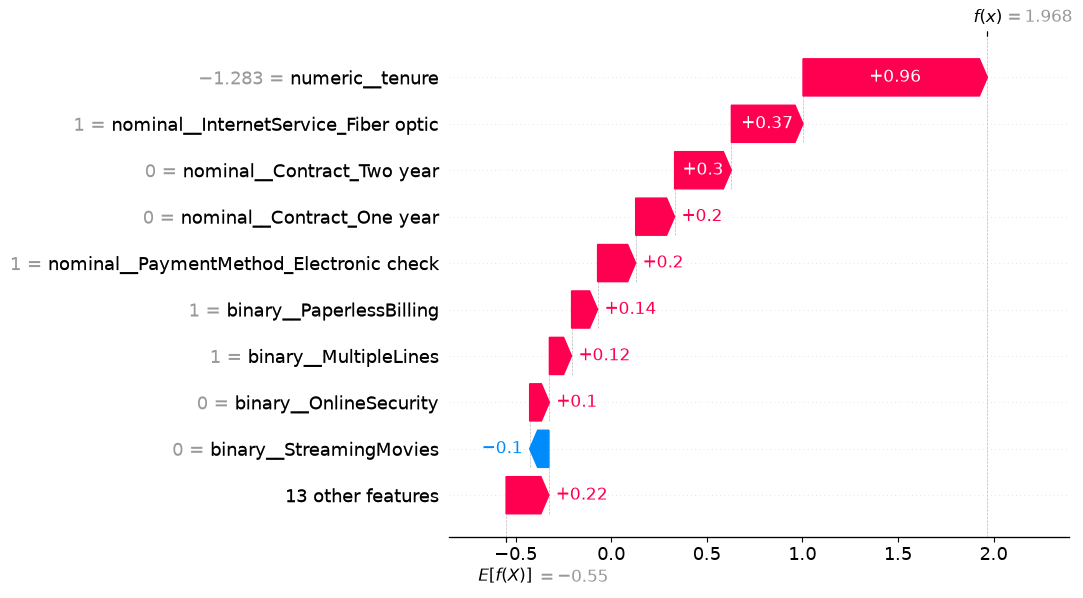

[[{'feature': 'tenure',
   'value': 1,
   'impact': 0.964,
   'effect': 'increases churn risk'},
  {'feature': 'Contract',
   'value': 'Month-to-month',
   'impact': 0.501,
   'effect': 'increases churn risk'},
  {'feature': 'InternetService',
   'value': 'Fiber optic',
   'impact': 0.459,
   'effect': 'increases churn risk'}]]

In [8]:
shap.plots.waterfall(sv[1])
explainer.top_reasons(X_sample.iloc[[1]], raw_test.iloc[[1]], original_cols)